# Week 4: PyTorch and the training loop (Gate 0) (solved)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/QuranLearning/ai-llm-deep-dive/blob/main/notebooks/week-04-pytorch-training-loop.ipynb)
· [Lesson text](https://github.com/QuranLearning/ai-llm-deep-dive/blob/main/lessons/week-04.md) · [Learning Hub week page](https://claude.ai/artifact/VwTfCas4FMnB23QHuBUJhj#w-ai-llm-4)

**By the end of this notebook you will:**
- use autograd and confirm it matches your hand-written gradients
- write the MLP as an `nn.Module`
- write a complete training loop with AdamW, warmup + cosine schedule, clipping, evaluation and checkpoints
- pass Gate 0

**Solved version.** Every exercise is filled in with working code. Read each cell, run the notebook top to bottom (*Runtime → Run all*), and use the **Check** cells to confirm the results. Change the code freely to experiment; the Check cells tell you if something breaks.

In [1]:
import math, numpy as np, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
torch.manual_seed(0); rng = np.random.default_rng(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
def ok(msg="Correct"): print("\u2705", msg)

def make_spirals(n=300, noise=0.2, seed=0):
    r = np.random.default_rng(seed)
    t = np.sqrt(r.uniform(0, 1, n)) * 3 * np.pi
    a = np.c_[t * np.cos(t), t * np.sin(t)]
    X = np.r_[a, -a] / 10 + r.normal(scale=noise / 10 * 3, size=(2 * n, 2))
    return X.astype(np.float32), np.r_[np.zeros(n, int), np.ones(n, int)]

X_all, y_all = make_spirals(400, noise=0.1)
idx = rng.permutation(len(y_all)); tr, va = idx[:640], idx[640:]
Xtr, ytr = torch.tensor(X_all[tr]), torch.tensor(y_all[tr]); Xva, yva = torch.tensor(X_all[va]), torch.tensor(y_all[va])
print("device:", device, "| train", Xtr.shape, "| val", Xva.shape)

device: cpu | train torch.Size([640, 2]) | val torch.Size([160, 2])


## Exercise 1: autograd warm-up
With `w = [2, -1]` (requires_grad) and `x = [3, 4]`, compute `loss = (w·x − 1)²` and call `backward()`. Store the gradient in `g`. The lesson works it out by hand: [6, 8].

In [2]:
w = torch.tensor([2.0, -1.0], requires_grad=True); x = torch.tensor([3.0, 4.0])
loss = (w @ x - 1) ** 2; loss.backward(); g = w.grad

In [3]:
assert g is not None and torch.allclose(g, torch.tensor([6., 8.]))
ok("autograd")

✅ autograd


## Exercise 2: the MLP as an `nn.Module`
`MLP(d, h, c)`: Linear → Tanh → Linear, returning **logits** (no softmax: `CrossEntropyLoss` does that).

In [4]:
class MLP(nn.Module):
    def __init__(self, d, h, c):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.Tanh(), nn.Linear(h, c))
    def forward(self, x):
        return self.net(x)

In [5]:
m = MLP(2, 16, 2); out = m(torch.zeros(5, 2))
assert out.shape == (5, 2)
assert sum(p.numel() for p in m.parameters()) == 2*16 + 16 + 16*2 + 2
ok("MLP module")

✅ MLP module


## Exercise 3: PyTorch matches your NumPy gradients
Below is the NumPy backward pass from week 3. Copy the same weights into an `MLP` (careful: `nn.Linear` stores weight as (out, in), so transpose) and set `max_diff` to the largest absolute difference between the PyTorch and NumPy gradients for W1. It should be below 1e-6.

In [6]:
def np_grads(W1, b1, W2, b2, X, y):
    H = np.tanh(X @ W1 + b1); Z = H @ W2 + b2; Z -= Z.max(1, keepdims=True)
    P = np.exp(Z); P /= P.sum(1, keepdims=True); N = len(y)
    dZ = P.copy(); dZ[np.arange(N), y] -= 1; dZ /= N
    dA = (dZ @ W2.T) * (1 - H**2)
    return X.T @ dA
W1, b1 = rng.normal(size=(2, 16)) / np.sqrt(2), np.zeros(16)
W2, b2 = rng.normal(size=(16, 2)) / 4, np.zeros(2)
Xn, yn = X_all[:32].astype(np.float64), y_all[:32]
gW1_np = np_grads(W1, b1, W2, b2, Xn, yn)
model_ = MLP(2, 16, 2).double()

with torch.no_grad():
    model_.net[0].weight.copy_(torch.tensor(W1.T)); model_.net[0].bias.copy_(torch.tensor(b1))
    model_.net[2].weight.copy_(torch.tensor(W2.T)); model_.net[2].bias.copy_(torch.tensor(b2))
nn.CrossEntropyLoss()(model_(torch.tensor(Xn)), torch.tensor(yn)).backward()
max_diff = np.abs(model_.net[0].weight.grad.numpy().T - gW1_np).max()

In [7]:
assert max_diff is not None and max_diff < 1e-6, max_diff
ok(f"gradients match (max diff {max_diff:.2e})")

✅ gradients match (max diff 1.39e-17)


## Exercise 4: the full training loop (write it from memory if you can)
Write `fit(epochs=400, hidden=128)` returning `(model, history)` where history is a list of validation losses. Required pieces: shuffled train `DataLoader` (batch 64), fixed val loader, `AdamW(lr=5e-2, weight_decay=0.01)`, linear warmup (5% of steps) then cosine decay to 10%, `zero_grad → backward → clip_grad_norm_(1.0) → step → scheduler.step`, `model.train()` / `model.eval()` with `torch.no_grad()`, and save the best checkpoint to `ckpt.pt` with model, optimizer, step and val loss.

In [8]:
def fit(epochs=400, hidden=128, seed=0):
    torch.manual_seed(seed)
    train_dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
    val_dl = DataLoader(TensorDataset(Xva, yva), batch_size=256)
    model = MLP(2, hidden, 2).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=5e-2, weight_decay=0.01)
    loss_fn = nn.CrossEntropyLoss()
    total = epochs * len(train_dl); warmup = max(1, int(0.05 * total))
    def lr_at(s):
        if s < warmup: return (s + 1) / warmup
        t = (s - warmup) / max(1, total - warmup)
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * t))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_at)
    step, best, hist = 0, float("inf"), []
    for _ in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); step += 1
        model.eval(); vl, n = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_dl:
                xb, yb = xb.to(device), yb.to(device)
                vl += loss_fn(model(xb), yb).item() * len(yb); n += len(yb)
        vl /= n; hist.append(vl)
        if vl < best:
            best = vl
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "step": step, "val": vl}, "ckpt.pt")
    model.load_state_dict(torch.load("ckpt.pt", map_location=device)["model"])
    return model, hist

validation accuracy 0.994, best val loss 0.0363


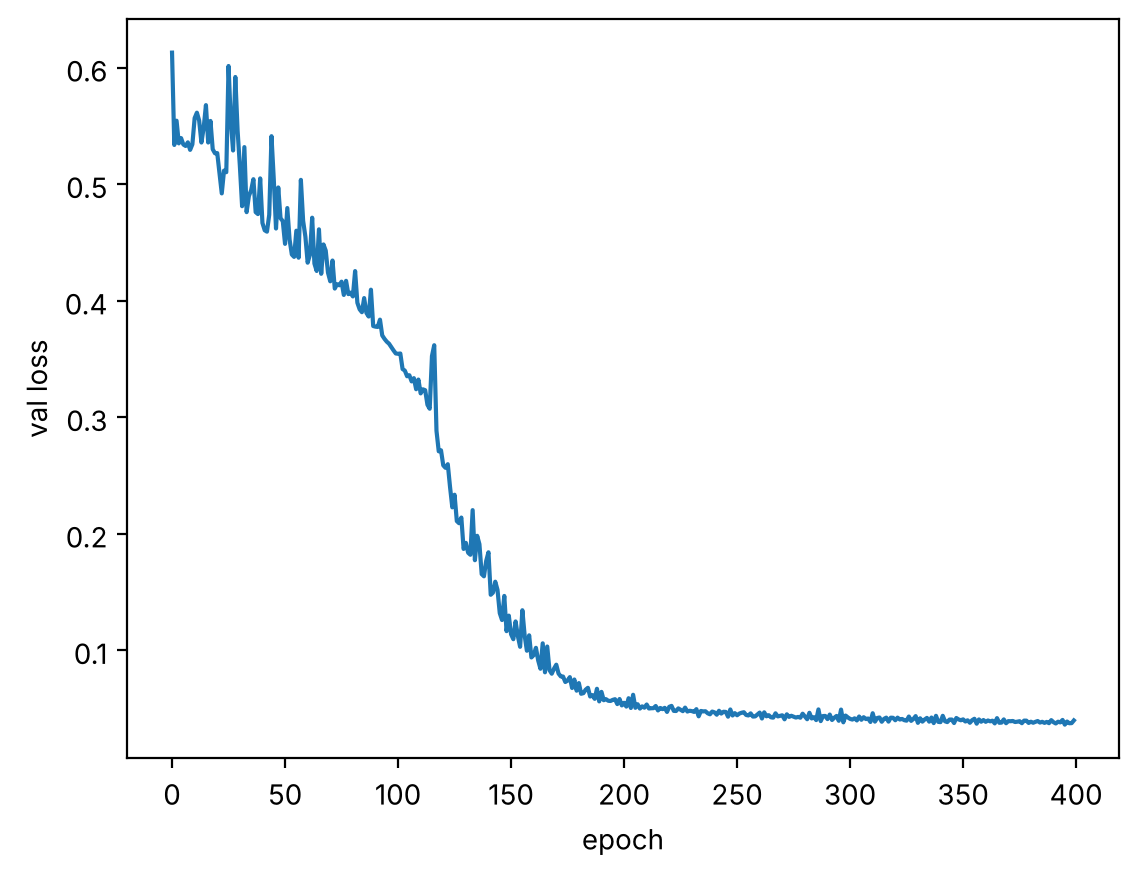

✅ training loop


In [9]:
model, hist = fit()
with torch.no_grad():
    acc = (model(Xva.to(device)).argmax(1).cpu() == yva).float().mean().item()
print(f"validation accuracy {acc:.3f}, best val loss {min(hist):.4f}")
assert acc > 0.95, "aim for > 95% validation accuracy"
ck = torch.load("ckpt.pt", map_location="cpu")
assert {"model", "opt", "step", "val"} <= set(ck), "checkpoint needs model, opt, step, val"
plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("val loss"); plt.show()
ok("training loop")

## Exercise 5: resume from the checkpoint
Rebuild a fresh `MLP`, load the saved state dict, and set `resumed_acc` to its validation accuracy. It must equal the best model's accuracy.

In [10]:
resumed_acc = None
import os

if not os.path.exists("ckpt.pt"): fit()   # make sure a checkpoint exists
fresh = MLP(2, 128, 2)
fresh.load_state_dict(torch.load("ckpt.pt", map_location="cpu")["model"]); fresh.eval()

with torch.no_grad():
    resumed_acc = (fresh(Xva).argmax(1) == yva).float().mean().item()

In [11]:
assert resumed_acc is not None and resumed_acc > 0.95
ok("checkpoint restored")

✅ checkpoint restored


## Gate 0 checklist
Tick these on the week page when they're true:
- PyTorch MLP matches your NumPy gradients (Exercise 3)
- Spirals solved with > 95% validation accuracy (Exercise 4)
- Training loop written from a blank file, without looking
- You can explain each piece of the loop in your own words
- Code pushed to your GitHub repo with a short README